<a href="https://colab.research.google.com/github/codeKrantz/AI-2010-FINAL-Project/blob/main/NCAA_Tournament_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NCAA March Madness AI 2010 Final Project
* Using data from Kaggle: https://www.kaggle.com/competitions/march-machine-learning-mania-2026/overview
* This notebook requires a KAGGLE_USERNAME and KAGGLE_KEY:


In [4]:
#@title Kaggle Username and API Key Validation
#this cell is used for crediential checking
from google.colab import userdata

u = userdata.get("KAGGLE_USERNAME")
k = userdata.get("KAGGLE_KEY")
print(repr(u))                       # should be your Kaggle username
print(len(k), k != k.strip())        # key length, and whether it has stray whitespace/newline

'conradkrantz'
39 True


In [5]:
#@title Kaggle Login
import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [6]:
#@title Data Importing from Kaggle
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

import kagglehub
import pandas as pd

path = kagglehub.competition_download("march-machine-learning-mania-2026")

# See what's there
files = sorted(os.listdir(path))
print(files)

# Load the men's files (they start with "M"); swap to "W" for women's
men = {
    f.replace(".csv", ""): pd.read_csv(os.path.join(path, f), encoding="latin-1")
    for f in files
    if f.startswith("M") and f.endswith(".csv")
}

for name, df in men.items():
    print(name, df.shape)

100%|██████████| 34.8M/34.8M [00:00<00:00, 101MB/s]

Extracting files...


['Cities.csv', 'Conferences.csv', 'MConferenceTourneyGames.csv', 'MGameCities.csv', 'MMasseyOrdinals.csv', 'MNCAATourneyCompactResults.csv', 'MNCAATourneyDetailedResults.csv', 'MNCAATourneySeedRoundSlots.csv', 'MNCAATourneySeeds.csv', 'MNCAATourneySlots.csv', 'MRegularSeasonCompactResults.csv', 'MRegularSeasonDetailedResults.csv', 'MSeasons.csv', 'MSecondaryTourneyCompactResults.csv', 'MSecondaryTourneyTeams.csv', 'MTeamCoaches.csv', 'MTeamConferences.csv', 'MTeamSpellings.csv', 'MTeams.csv', 'SampleSubmissionStage1.csv', 'SampleSubmissionStage2.csv', 'WConferenceTourneyGames.csv', 'WGameCities.csv', 'WNCAATourneyCompactResults.csv', 'WNCAATourneyDetailedResults.csv', 'WNCAATourneySeeds.csv', 'WNCAATourneySlots.csv', 'WRegularSeasonCompactResults.csv', 'WRegularSeasonDetailedResults.csv', 'WSeasons.csv', 'WSecondaryTourneyCompactResults.csv', 'WSecondaryTourneyTeams.csv', 'WTeamConferences.csv', 'WTeamSpellings.csv', 'WTeams.csv']
MConferenceTourneyGames (7093, 5)
MGameCities (92438, 6

In [7]:
print(path)

/root/.cache/kagglehub/competitions/march-machine-learning-mania-2026


In [8]:
import pandas as pd
df = pd.read_csv(os.path.join(path, "MRegularSeasonDetailedResults.csv"))

In [9]:
df

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT,WFGM,WFGA,...,LFGA3,LFTM,LFTA,LOR,LDR,LAst,LTO,LStl,LBlk,LPF
0,2003,10,1104,68,1328,62,N,0,27,58,...,10,16,22,10,22,8,18,9,2,20
1,2003,10,1272,70,1393,63,N,0,26,62,...,24,9,20,20,25,7,12,8,6,16
2,2003,11,1266,73,1437,61,N,0,24,58,...,26,14,23,31,22,9,12,2,5,23
3,2003,11,1296,56,1457,50,N,0,18,38,...,22,8,15,17,20,9,19,4,3,23
4,2003,11,1400,77,1208,71,N,0,30,61,...,16,17,27,21,15,12,10,7,1,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124524,2026,132,1335,88,1463,84,N,1,29,64,...,24,13,17,17,24,23,9,9,4,16
124525,2026,132,1345,80,1276,72,N,0,30,57,...,24,5,6,11,22,15,7,2,3,18
124526,2026,132,1378,70,1455,55,N,0,23,61,...,19,13,20,12,27,8,14,7,7,19
124527,2026,132,1433,70,1173,62,N,0,23,57,...,21,9,17,8,31,16,11,3,4,18


## Data Cleaning

In [10]:
#@title Load the data files used by the model
import os
import pandas as pd

# `path` is set by the Kaggle download cell above.
# Only the 4 files the models need are loaded here.
FILES = {
    "rs":      "MRegularSeasonDetailedResults.csv",  # features: regular-season box scores (2003+)
    "tourney": "MNCAATourneyDetailedResults.csv",    # labels: who won each NCAA tournament game
    "seeds":   "MNCAATourneySeeds.csv",              # seed-only baseline model
    "teams":   "MTeams.csv",                         # TeamID -> school name for readable output
}

missing = [f for f in FILES.values() if not os.path.exists(os.path.join(path, f))]
assert not missing, f"Missing files in {path}: {missing}"

def load(key):
    return pd.read_csv(os.path.join(path, FILES[key]), encoding="latin-1")

rs      = load("rs")
tourney = load("tourney")
seeds   = load("seeds")
teams   = load("teams")

# Summary of what was loaded
summary = pd.DataFrame([
    {
        "variable": name,
        "file": FILES[name],
        "rows": len(d),
        "columns": d.shape[1],
        "seasons": f"{d.Season.min()}-{d.Season.max()}" if "Season" in d else "-",
    }
    for name, d in {"rs": rs, "tourney": tourney, "seeds": seeds, "teams": teams}.items()
])
print(summary.to_string(index=False))

variable                              file   rows  columns   seasons
      rs MRegularSeasonDetailedResults.csv 124529       34 2003-2026
 tourney   MNCAATourneyDetailedResults.csv   1449       34 2003-2025
   seeds             MNCAATourneySeeds.csv   2694        3 1985-2026
   teams                        MTeams.csv    381        4         -


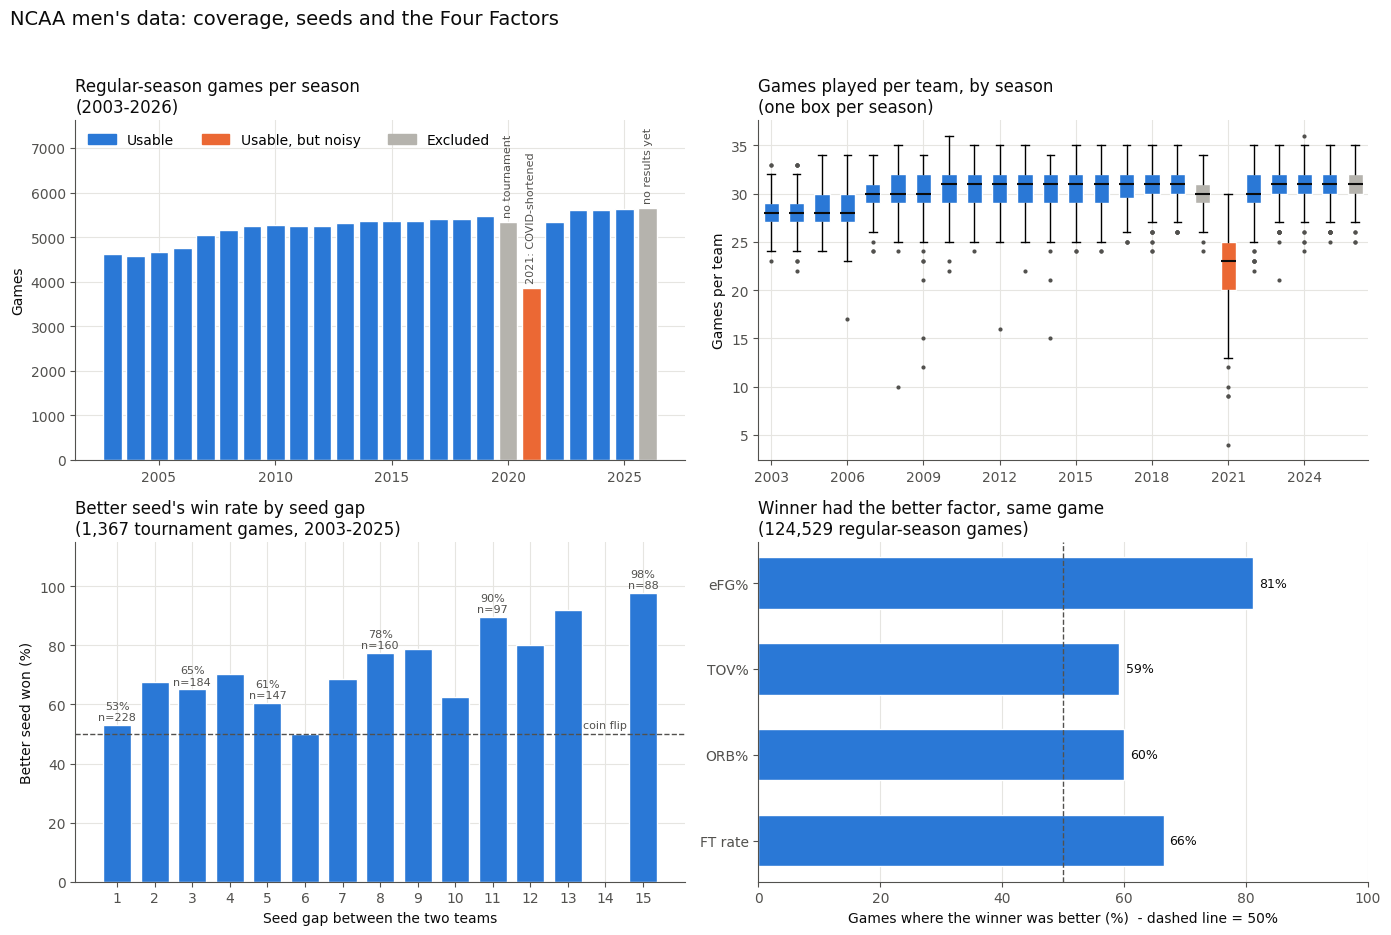

In [12]:
#@title Visualize the loaded data (exclude 2020 and acknowledge the reduced data from 2021 due to Covid)
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

# Seasons that can't be used for training/testing
EXCLUDED = {2020: "no tournament", 2026: "no results yet"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
fig.suptitle("NCAA men's data: coverage, seeds and the Four Factors", fontsize=14, x=0.01, ha="left", color=INK)

# 1. Regular-season games per season ------------------------------------
ax = axes[0, 0]
per_season = rs.groupby("Season").size()
colors = [GRAY if s in EXCLUDED else (ORANGE if s == 2021 else BLUE) for s in per_season.index]
ax.bar(per_season.index, per_season.values, color=colors, width=0.8, edgecolor="white", linewidth=1)
for s, why in EXCLUDED.items():
    ax.annotate(why, (s, per_season[s]), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8, color=MUTED, rotation=90, va="bottom")
ax.annotate("2021: COVID-shortened", (2021, per_season[2021]), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=8, color=MUTED, rotation=90, va="bottom")
ax.set_title("Regular-season games per season\n(2003-2026)", loc="left", color=INK)
ax.set_ylabel("Games")
ax.set_ylim(0, per_season.max() * 1.35)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, GRAY)],
          labels=["Usable", "Usable, but noisy", "Excluded"], frameon=False, loc="upper left", ncol=3)

# 2. Games per team per season (shows how thin 2021 is) -----------------
ax = axes[0, 1]
long = pd.concat([rs[["Season", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                  rs[["Season", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
gp = long.groupby(["Season", "TeamID"]).size().rename("games").reset_index()
seasons = sorted(gp.Season.unique())
bp = ax.boxplot([gp.loc[gp.Season == s, "games"] for s in seasons], positions=seasons,
                widths=0.6, patch_artist=True, showfliers=True,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"),
                medianprops=dict(color=INK, linewidth=1.5))
for patch, s in zip(bp["boxes"], seasons):
    patch.set_facecolor(GRAY if s in EXCLUDED else (ORANGE if s == 2021 else BLUE))
    patch.set_edgecolor("white")
ax.set_title("Games played per team, by season\n(one box per season)", loc="left", color=INK)
ax.set_ylabel("Games per team")
ax.set_xticks(seasons[::3], labels=[str(x) for x in seasons[::3]])

# 3. Higher seed's win rate by seed gap (seed-only baseline) ------------
ax = axes[1, 0]
s = seeds.assign(SeedNum=seeds.Seed.str[1:3].astype(int))[["Season", "TeamID", "SeedNum"]]
t = (tourney.merge(s.rename(columns={"TeamID": "WTeamID", "SeedNum": "WSeed"}), on=["Season", "WTeamID"])
            .merge(s.rename(columns={"TeamID": "LTeamID", "SeedNum": "LSeed"}), on=["Season", "LTeamID"]))
t["gap"] = (t.WSeed - t.LSeed).abs()
t = t[t.gap > 0]                                   # same-seed games (mostly First Four) have no favorite
t["fav_won"] = t.WSeed < t.LSeed
by_gap = t.groupby("gap").fav_won.agg(["mean", "size"])
ax.bar(by_gap.index, by_gap["mean"] * 100, color=BLUE, width=0.75, edgecolor="white", linewidth=1)
ax.axhline(50, color=MUTED, linewidth=1, linestyle="--")
ax.text(14, 51.5, "coin flip", fontsize=8, color=MUTED, ha="center", va="bottom")
for g, row in by_gap.iterrows():
    if g in (1, 3, 5, 8, 11, 15):
        ax.text(g, row["mean"] * 100 + 1.5, f"{row['mean']:.0%}\nn={int(row['size'])}",
                ha="center", fontsize=8, color=MUTED)
ax.set_title(f"Better seed's win rate by seed gap\n({len(t):,} tournament games, 2003-2025)", loc="left", color=INK)
ax.set_xlabel("Seed gap between the two teams")
ax.set_ylabel("Better seed won (%)")
ax.set_ylim(0, 115)
ax.set_xticks(range(1, 16))

# 4. How often the winner had the better Four Factor ---------------------
ax = axes[1, 1]
def factors(p, o):
    return pd.DataFrame({
        "eFG%":     (rs[p+"FGM"] + 0.5 * rs[p+"FGM3"]) / rs[p+"FGA"],
        "TOV%":     rs[p+"TO"] / (rs[p+"FGA"] + 0.44 * rs[p+"FTA"] + rs[p+"TO"]),
        "ORB%":     rs[p+"OR"] / (rs[p+"OR"] + rs[o+"DR"]),
        "FT rate":  rs[p+"FTA"] / rs[p+"FGA"],
    })
w, l = factors("W", "L"), factors("L", "W")
better = {
    "eFG%":    (w["eFG%"] > l["eFG%"]).mean(),
    "TOV%":    (w["TOV%"] < l["TOV%"]).mean(),     # fewer turnovers is better
    "ORB%":    (w["ORB%"] > l["ORB%"]).mean(),
    "FT rate": (w["FT rate"] > l["FT rate"]).mean(),
}
names, vals = list(better), [v * 100 for v in better.values()]
bars = ax.barh(names[::-1], vals[::-1], color=BLUE, height=0.6, edgecolor="white", linewidth=1)
ax.axvline(50, color=MUTED, linewidth=1, linestyle="--")
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_title(f"Winner had the better factor, same game\n({len(rs):,} regular-season games)",
             loc="left", color=INK)
ax.set_xlabel("Games where the winner was better (%)  - dashed line = 50%")
ax.grid(axis="y", visible=False)

fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()